# Day 1 · Baseline vs. boosting on Tamweel Lite

Goal: train Logistic Regression, XGBoost and LightGBM on the same rows, compare how well each one *ranks* risky applications (ROC-AUC, Average Precision) and how long it takes to train, then pick an initial candidate using numbers from this run.

## 1. Set up the environment

The setup cell fetches the pinned course files, verifies their SHA-256 hashes and installs the pinned package versions. If a checksum or an already-imported package version fails, do not work around it: restart the session and run again from the top.

In [14]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

# Pinned course release (the setup helper refuses anything whose hash differs).
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
# Course reference lab that this notebook's results are checked against (parity record only).
LAB_REVISION = "c8344f6b19b26dcbce3dcfc671b746c59bf55895"
LAB_SHA256 = "2a968ba9e738cc5e3dae12077e576fdb40ec6ec64230613e445bbc7884e7e1ba"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)


def file_digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


setup_script = ROOT / "scripts" / "setup_colab.py"
setup_script.parent.mkdir(parents=True, exist_ok=True)
if not setup_script.exists() or file_digest(setup_script) != SETUP_SHA256:
    setup_url = ("https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/"
                 f"{COURSE_REVISION}/scripts/setup_colab.py")
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Re-open the released notebook.")
            setup_script.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_script))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)
print("Day 1 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 1 setup verified


## 2. Task, data and settings

All records are synthetic. The target `default_within_90d` is 1 when a default event happens within 90 days of the application (it does not mean a delay of exactly 90 days). The model sees the 22 features known at application time; identifiers, dates and the target are never inputs. Missing values are imputed with medians learned from training rows only. The challenge file is not used today.

In [15]:
import json
import platform
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lightgbm import LGBMClassifier, early_stopping, record_evaluation
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from data_checks import load_course_data

warnings.filterwarnings("ignore", message="scipy.optimize:.*disp.*", category=DeprecationWarning)

FAST_MODE = True  # True: up to 300 trees. False: optional 900-tree run after the baseline is saved.
SEED, N_JOBS = 211, 2
MODELS = ("Logistic Regression", "XGBoost", "LightGBM")

CFG = {
    "seed": SEED,
    "n_jobs": N_JOBS,
    "max_trees": 300 if FAST_MODE else 900,   # search ceiling, not a required tree count
    "patience": 30,                           # rounds without inner-stop improvement before stopping
    "learning_rate": 0.05,
    "xgb_depth": 3,
    "lgb_leaves": 15,
    "min_child_samples": 50,
}
assert 0 < CFG["learning_rate"] <= 1 and 1 <= CFG["n_jobs"] <= 2
assert 1 <= CFG["patience"] < CFG["max_trees"] <= 1200
assert 1 <= CFG["xgb_depth"] <= 8 and 2 <= CFG["lgb_leaves"] <= 63 and CFG["min_child_samples"] >= 2

frames, contract, data_summary = load_course_data(ROOT)
train = frames["train"]
TARGET = contract["target"]["name"]
FEATURES = [item["name"] for item in contract["features"]]

ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)

display(pd.DataFrame({"rows": [len(train)], "features": [len(FEATURES)],
                      "positive_rate": [train[TARGET].mean()],
                      "missing_cells": [int(train[FEATURES].isna().sum().sum())]}))
display(train[["application_id", "income_sar", "bureau_score", TARGET]].head(3))

,rows,features,positive_rate,missing_cells
0,10000,22,0.0789,766


,application_id,income_sar,bureau_score,default_within_90d
0,TR-001121,8938.11,584.0,0
1,TR-002836,16995.65,652.0,0
2,TR-005579,8353.27,734.0,0


## 3. Give every row exactly one job

| Role | Rows | What it is used for |
|---|---:|---|
| Development | 8,000 | final refit of each model once its settings are frozen |
| Inner fit | 6,000 (inside development) | learns imputation and trees while the tree count is being chosen |
| Inner stop | 2,000 (inside development) | decides when to stop adding trees (log loss) |
| Comparison | 2,000 | scores every model once, at the very end |

The two inner sets are slices of development, not extra data. The comparison rows must never influence early stopping or repeated tuning.

In [16]:
def assign_roles(frame, seed):
    """Stratified random roles. A teaching baseline only: customers and time are ignored."""
    if not (frame.index.is_unique and frame["application_id"].is_unique):
        raise ValueError("Row index and application_id must both be unique.")
    banned = set(contract["metadata"]) | {TARGET}
    if banned & set(FEATURES):
        raise ValueError("Metadata or the target leaked into the feature list.")
    labels = frame[TARGET]
    if set(labels.unique()) != {0, 1} or labels.value_counts().min() < 10:
        raise ValueError("Both classes need at least 10 examples.")
    dev_rows, cmp_rows = train_test_split(
        frame.index.to_numpy(), test_size=0.2, stratify=labels, random_state=seed)
    fit_rows, stop_rows = train_test_split(
        dev_rows, test_size=0.25, stratify=labels.loc[dev_rows], random_state=seed + 1)
    roles = {"development": dev_rows, "comparison": cmp_rows,
             "inner_fit": fit_rows, "inner_stop": stop_rows}
    return frame[FEATURES].copy(), labels.copy(), roles


X, y, roles = assign_roles(train, CFG["seed"])
development, comparison = roles["development"], roles["comparison"]
inner_fit, inner_stop = roles["inner_fit"], roles["inner_stop"]

assert not set(development) & set(comparison)
assert not set(inner_fit) & set(inner_stop)
assert set(inner_fit) | set(inner_stop) == set(development)

split_table = pd.DataFrame([{"role": name, "rows": len(rows), "positive_rate": y.loc[rows].mean()}
                            for name, rows in roles.items()])
shared_customers = len(set(train.loc[development, "customer_id"]) & set(train.loc[comparison, "customer_id"]))
display(split_table)
print(f"Customers present in both development and comparison: {shared_customers} (a leak we leave for Day 2)")

models, timings, selections = {}, {}, {}

,role,rows,positive_rate
0,development,8000,0.078875
1,comparison,2000,0.079000
2,inner_fit,6000,0.078833
3,inner_stop,2000,0.079000


Customers present in both development and comparison: 1226 (a leak we leave for Day 2)


## 4. Helpers: model factories, tree-count search, refit, scoring

Boosting adds trees one after another; under a logistic objective the trees add up in log-odds space and the sum is converted to a probability afterwards. `selected_trees` below is one-based. Logistic Regression has no tree count. Class weights are deliberately left for a later lab.

In [17]:
def _shared_boost_args(n_trees):
    return dict(n_estimators=int(n_trees), learning_rate=CFG["learning_rate"],
                random_state=CFG["seed"], n_jobs=CFG["n_jobs"],
                subsample=0.8, colsample_bytree=0.8)


def new_xgb(n_trees, stopping=False):
    args = dict(tree_method="hist", max_depth=CFG["xgb_depth"], objective="binary:logistic",
                eval_metric="logloss", **_shared_boost_args(n_trees))
    if stopping:
        args["early_stopping_rounds"] = CFG["patience"]
    return XGBClassifier(**args)


def new_lgbm(n_trees):
    return LGBMClassifier(objective="binary", metric="binary_logloss",
                          num_leaves=CFG["lgb_leaves"], min_child_samples=CFG["min_child_samples"],
                          subsample_freq=1, deterministic=True, force_col_wise=True,
                          verbosity=-1, **_shared_boost_args(n_trees))


def pick_tree_count(kind, X_fit, y_fit, X_stop, y_stop):
    """Choose a tree count from inner rows only; comparison rows are never passed in."""
    if set(X_fit.index) & set(X_stop.index):
        raise ValueError("Stop rows must be separate from fit rows.")
    started = time.perf_counter()
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    fit_part = pd.DataFrame(imputer.fit_transform(X_fit), columns=X_fit.columns, index=X_fit.index)
    stop_part = pd.DataFrame(imputer.transform(X_stop), columns=X_fit.columns, index=X_stop.index)
    watch = [(fit_part, y_fit), (stop_part, y_stop)]
    if kind == "XGBoost":
        booster = new_xgb(CFG["max_trees"], stopping=True)
        booster.fit(fit_part, y_fit, eval_set=watch, verbose=False)
        log = booster.evals_result()
        curves = {"fit": log["validation_0"]["logloss"], "stop": log["validation_1"]["logloss"]}
        chosen = int(booster.best_iteration) + 1          # XGBoost counts rounds from zero
    elif kind == "LightGBM":
        log = {}
        booster = new_lgbm(CFG["max_trees"])
        booster.fit(fit_part, y_fit, eval_set=watch, eval_names=["fit", "stop"],
                    eval_metric="binary_logloss",
                    callbacks=[early_stopping(CFG["patience"], first_metric_only=True, verbose=False),
                               record_evaluation(log)])
        curves = {part: log[part]["binary_logloss"] for part in ("fit", "stop")}
        chosen = int(booster.best_iteration_)
    else:
        raise ValueError(f"No tree count for {kind}")
    return {"model": kind, "selected_trees": chosen,
            "selection_seconds": time.perf_counter() - started,
            "rounds_evaluated": len(curves["stop"]), "curves": curves,
            "inner_imputer_medians": imputer.statistics_.tolist(),
            "hit_tree_budget": chosen == CFG["max_trees"]}


def refit_on_development(kind, X_dev, y_dev, selection=None):
    """Refit one model on all development rows after its settings are frozen."""
    started = time.perf_counter()
    steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    if kind == "Logistic Regression":
        steps += [("scale", StandardScaler()),
                  ("model", LogisticRegression(max_iter=1000, random_state=CFG["seed"]))]
    elif kind in ("XGBoost", "LightGBM"):
        if selection is None or selection["model"] != kind:
            raise ValueError("Freeze this model's tree count on the inner split first.")
        steps[0][1].set_output(transform="pandas")        # keep column names for LightGBM
        factory = new_xgb if kind == "XGBoost" else new_lgbm
        steps.append(("model", factory(selection["selected_trees"])))
    else:
        raise ValueError(f"Unknown model: {kind}")
    pipeline = Pipeline(steps).fit(X_dev, y_dev)
    refit = time.perf_counter() - started
    chosen_cost = 0.0 if selection is None else selection["selection_seconds"]
    return pipeline, {"selection_seconds": chosen_cost, "refit_seconds": refit,
                      "train_seconds": chosen_cost + refit}


def score_all(fitted, cost, picks, X_cmp, y_cmp):
    """Score every frozen model once. AP = sklearn average precision (not trapezoidal PR area)."""
    if set(fitted) != set(MODELS) or set(y_cmp.unique()) != {0, 1}:
        raise ValueError("Need all three models and both classes in the comparison rows.")
    table, scores = [], pd.DataFrame(index=X_cmp.index)
    for kind in MODELS:
        tick = time.perf_counter()
        p = fitted[kind].predict_proba(X_cmp)[:, 1]
        predict_seconds = time.perf_counter() - tick
        if not (np.isfinite(p).all() and p.min() >= 0 and p.max() <= 1):
            raise ValueError("Predictions must be finite probabilities.")
        scores[kind] = p
        picked = picks.get(kind)
        table.append({"model": kind,
                      "roc_auc": roc_auc_score(y_cmp, p),
                      "average_precision": average_precision_score(y_cmp, p),
                      **cost[kind], "predict_seconds": predict_seconds,
                      "selected_trees": None if picked is None else picked["selected_trees"],
                      "comparison_rows": len(y_cmp),
                      "positive_rate": float(y_cmp.mean())})
    return pd.DataFrame(table), scores

## 5. Start with the simple baseline

One pipeline: median imputation → standardisation → Logistic Regression, with every learned value coming from development rows only. A fancier model has to beat a credible simple one before it earns its extra complexity.

In [18]:
kind = "Logistic Regression"
models[kind], timings[kind] = refit_on_development(kind, X.loc[development], y.loc[development])
print(f"{kind}: fitted on {len(development):,} rows in {timings[kind]['train_seconds']:.3f} s")

Logistic Regression: fitted on 8,000 rows in 0.040 s


## 6. Boosting with early stopping

For each booster: find the tree count on the inner rows, freeze it, then refit on all development rows. The comparison rows stay untouched throughout.

In [19]:
for kind in ("XGBoost", "LightGBM"):
    selections[kind] = pick_tree_count(kind, X.loc[inner_fit], y.loc[inner_fit],
                                       X.loc[inner_stop], y.loc[inner_stop])
    models[kind], timings[kind] = refit_on_development(kind, X.loc[development], y.loc[development],
                                                       selections[kind])
    pick = selections[kind]
    print(f"{kind}: {pick['selected_trees']} trees chosen after {pick['rounds_evaluated']} rounds; "
          f"{timings[kind]['train_seconds']:.3f} s for selection + refit")
    if pick["hit_tree_budget"]:
        print("  Tree ceiling reached - note this limitation before trying FULL mode.")

XGBoost: 61 trees chosen after 91 rounds; 0.376 s for selection + refit
LightGBM: 41 trees chosen after 71 rounds; 0.239 s for selection + refit


### Learning curves

Solid line: loss on the rows the trees were fitted on. Dashed line: loss on the inner-stop rows. The dotted vertical line is the chosen tree count. Falling training loss alone proves nothing; what matters is where the inner-stop loss stops improving.

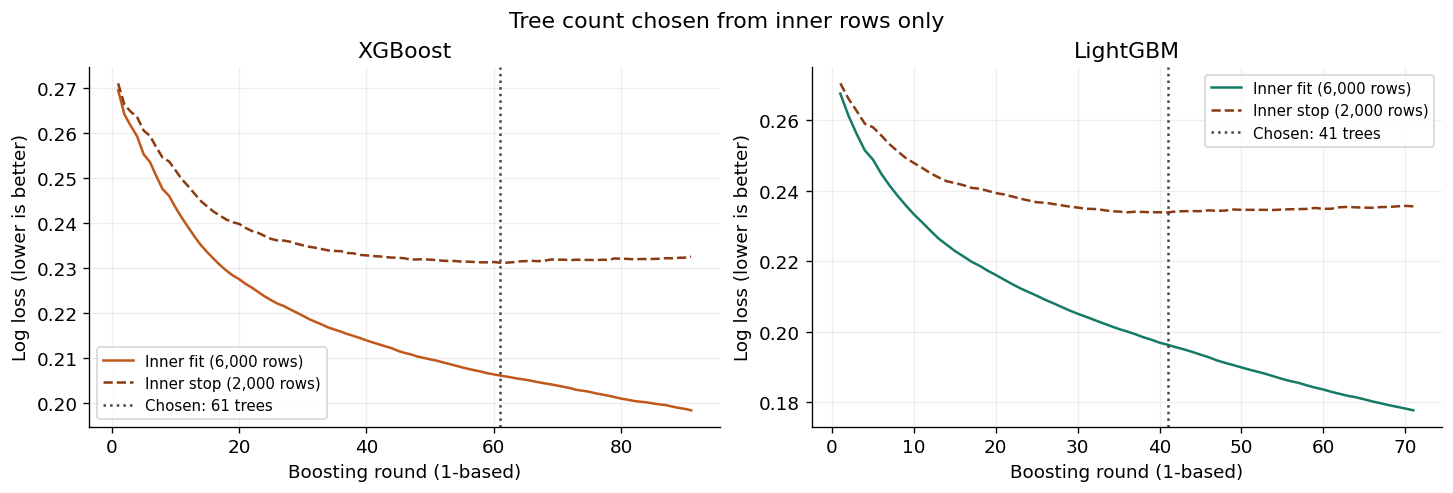

In [20]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
PALETTE = {"Logistic Regression": "#1F5F8B", "XGBoost": "#C2571A", "LightGBM": "#157A66"}

fig, panels = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for panel, (kind, pick) in zip(panels, selections.items()):
    rounds = np.arange(1, len(pick["curves"]["fit"]) + 1)
    panel.plot(rounds, pick["curves"]["fit"], color=PALETTE[kind], label=f"Inner fit ({len(inner_fit):,} rows)")
    panel.plot(rounds, pick["curves"]["stop"], color="#8A3B12", linestyle="--",
               label=f"Inner stop ({len(inner_stop):,} rows)")
    panel.axvline(pick["selected_trees"], color="#444444", linestyle=":",
                  label=f"Chosen: {pick['selected_trees']} trees")
    panel.set(title=kind, xlabel="Boosting round (1-based)", ylabel="Log loss (lower is better)")
    panel.legend(fontsize=9)
fig.suptitle("Tree count chosen from inner rows only")
fig.savefig(ARTIFACTS / "day1_learning_curves.png", dpi=160)
plt.show()

## 7. Compare the three models on the untouched comparison rows

* **ROC-AUC** - how well positives are ranked above negatives across all thresholds.
* **Average Precision (AP)** - summarises the precision-recall curve and is more informative when positives are rare. Here PR-AUC always means scikit-learn's average precision.
* **train_seconds** - tree-count search plus refit for the boosters, plain fitting for Logistic Regression; downloads and plotting are excluded. It is an observation from this run, not a hardware guarantee.

One split gives no confidence interval and says nothing about calibration or business value. Cost (10 x FN + FP) and review capacity come in a later lab.

In [21]:
comparison_table, probabilities = score_all(models, timings, selections,
                                            X.loc[comparison], y.loc[comparison])
comparison_table["selected_trees"] = comparison_table["selected_trees"].astype("Int64")
display(comparison_table[["model", "roc_auc", "average_precision", "train_seconds",
                          "selected_trees", "comparison_rows", "positive_rate"]].round(4))

comparison_table.to_csv(ARTIFACTS / "day1_model_comparison.csv", index=False)
prediction_export = train.loc[comparison, ["application_id", TARGET]].join(probabilities)
prediction_export.to_csv(ARTIFACTS / "day1_comparison_predictions.csv", index=False)

assert len(comparison_table) == 3
assert comparison_table[["roc_auc", "average_precision", "train_seconds"]].notna().all().all()
print("TECHNICAL_READY: three models compared. Interpreting the numbers is still your job.")

,model,roc_auc,average_precision,train_seconds,selected_trees,comparison_rows,positive_rate
0,Logistic Regression,0.8213,0.3258,0.0396,<NA>,2000,0.079
1,XGBoost,0.8124,0.3338,0.3757,61,2000,0.079
2,LightGBM,0.8138,0.3248,0.2390,41,2000,0.079


TECHNICAL_READY: three models compared. Interpreting the numbers is still your job.


### ROC and precision-recall side by side

The dotted ROC diagonal is random ranking; the dotted precision line is the share of positives in the comparison rows. Look at how far the curves separate (especially precision at high recall), not just at one headline number, and remember a higher curve on one random split only describes this run.

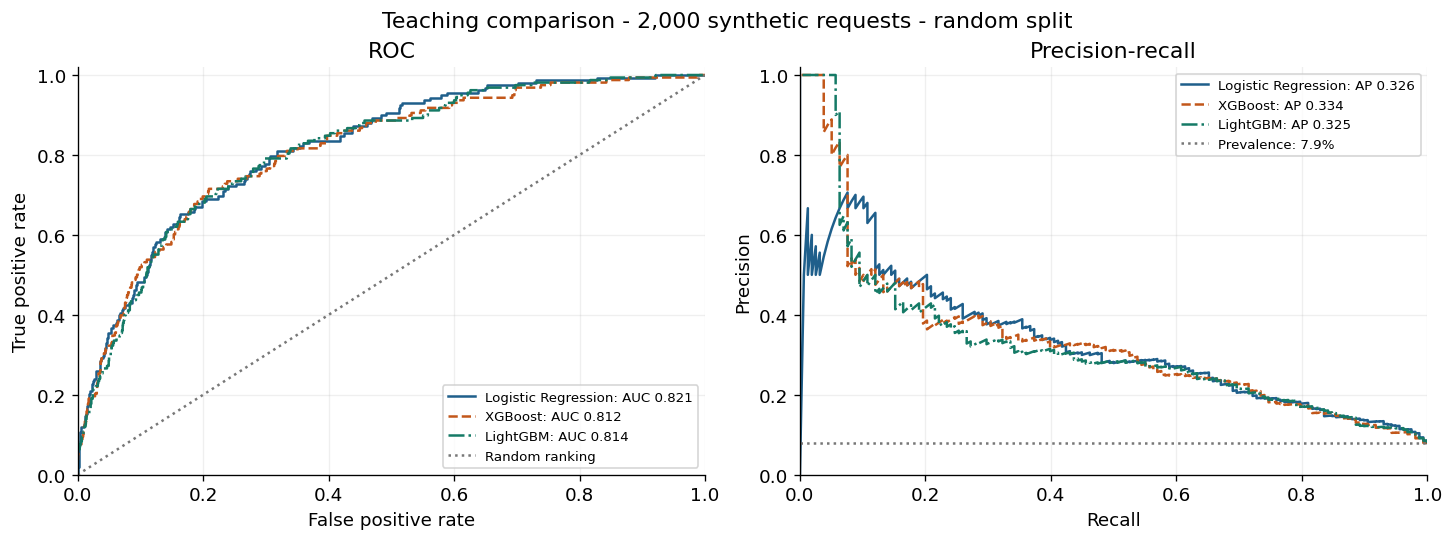

In [22]:
y_cmp = y.loc[comparison]
fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for kind, dash in zip(MODELS, ["-", "--", "-."]):
    fpr, tpr, _ = roc_curve(y_cmp, probabilities[kind])
    prec, rec, _ = precision_recall_curve(y_cmp, probabilities[kind])
    stats = comparison_table.set_index("model").loc[kind]
    roc_ax.plot(fpr, tpr, color=PALETTE[kind], linestyle=dash, label=f"{kind}: AUC {stats.roc_auc:.3f}")
    pr_ax.plot(rec, prec, color=PALETTE[kind], linestyle=dash, label=f"{kind}: AP {stats.average_precision:.3f}")
roc_ax.plot([0, 1], [0, 1], color="#777777", linestyle=":", label="Random ranking")
pr_ax.axhline(y_cmp.mean(), color="#777777", linestyle=":", label=f"Prevalence: {y_cmp.mean():.1%}")
roc_ax.set(title="ROC", xlabel="False positive rate", ylabel="True positive rate")
pr_ax.set(title="Precision-recall", xlabel="Recall", ylabel="Precision")
for panel in (roc_ax, pr_ax):
    panel.set_xlim(0, 1)
    panel.set_ylim(0, 1.02)
roc_ax.legend(fontsize=8, loc="lower right")
pr_ax.legend(fontsize=8, loc="upper right")
fig.suptitle(f"Teaching comparison - {len(y_cmp):,} synthetic requests - random split")
fig.savefig(ARTIFACTS / "day1_roc_pr.png", dpi=160)
plt.show()

## 8. Extra check: are the gaps bigger than noise?

The course table has no uncertainty. A paired bootstrap on the 2,000 comparison rows (same resampled rows for every model, 1,000 draws) shows how much the metrics wobble. This does **not** touch the fitted models or tune anything, so the comparison rows are still used for scoring only. It is saved as an extra file, `day1_bootstrap_check.csv`.

In [23]:
rng = np.random.default_rng(CFG["seed"])
labels_cmp = y_cmp.to_numpy()
score_matrix = probabilities[list(MODELS)].to_numpy()
N_DRAWS = 1000

draw_auc, draw_ap = [], []
while len(draw_auc) < N_DRAWS:
    pick_rows = rng.integers(0, len(labels_cmp), len(labels_cmp))
    sample = labels_cmp[pick_rows]
    if sample.min() == sample.max():
        continue
    draw_auc.append([roc_auc_score(sample, score_matrix[pick_rows, j]) for j in range(3)])
    draw_ap.append([average_precision_score(sample, score_matrix[pick_rows, j]) for j in range(3)])
draw_auc, draw_ap = np.array(draw_auc), np.array(draw_ap)

point = comparison_table.set_index("model")
rows = []
for metric, draws, column in (("roc_auc", draw_auc, "roc_auc"), ("average_precision", draw_ap, "average_precision")):
    for j, kind in enumerate(MODELS):
        low, high = np.percentile(draws[:, j], [2.5, 97.5])
        entry = {"model": kind, "metric": metric, "estimate": point.loc[kind, column],
                 "ci95_low": low, "ci95_high": high}
        if j == 0:
            entry.update(delta_vs_logreg=np.nan, delta_ci95_low=np.nan, delta_ci95_high=np.nan,
                         share_of_draws_better_than_logreg=np.nan)
        else:
            diff = draws[:, j] - draws[:, 0]
            d_low, d_high = np.percentile(diff, [2.5, 97.5])
            entry.update(delta_vs_logreg=point.loc[kind, column] - point.loc[MODELS[0], column],
                         delta_ci95_low=d_low, delta_ci95_high=d_high,
                         share_of_draws_better_than_logreg=float((diff > 0).mean()))
        rows.append(entry)
bootstrap_table = pd.DataFrame(rows)
bootstrap_table.to_csv(ARTIFACTS / "day1_bootstrap_check.csv", index=False)
display(bootstrap_table.round(4))

,model,metric,estimate,ci95_low,ci95_high,delta_vs_logreg,delta_ci95_low,delta_ci95_high,share_of_draws_better_than_logreg
0,Logistic Regression,roc_auc,0.8213,0.7872,0.8536,NaN,NaN,NaN,NaN
1,XGBoost,roc_auc,0.8124,0.7753,0.8479,-0.0088,-0.0195,0.0032,0.076
2,LightGBM,roc_auc,0.8138,0.7765,0.8480,-0.0074,-0.0189,0.0047,0.119
3,Logistic Regression,average_precision,0.3258,0.2563,0.4033,NaN,NaN,NaN,NaN
4,XGBoost,average_precision,0.3338,0.2606,0.4052,0.0081,-0.0304,0.0359,0.597
5,LightGBM,average_precision,0.3248,0.2559,0.3944,-0.0009,-0.0459,0.0296,0.412


## 9. Own the model-selection decision

Written from this run's numbers: the problem statement, one candidate, the strongest piece of evidence, what this experiment cannot prove, and the test that could change my mind, plus answers to the two exit questions. The automatic checkpoint below only detects empty fields; it does not grade anything.

In [26]:
problem_statement = 'Predict whether a synthetic loan applicant will have a default event within 90 days of applying, using only the 22 features known at application time. The model is meant to rank applications by risk at decision time. Today it is used only to learn how three model families compare on one random split; it is not a deployment estimate.'
candidate = 'Logistic Regression'
notes = {
    "evidence": 'Logistic Regression had the highest ROC-AUC (0.821 vs 0.812 for XGBoost and 0.814 for LightGBM) and a practically tied Average Precision (0.326 vs 0.334 and 0.325, against a 7.9% prevalence baseline), while training in 0.04 s versus 0.38 s for XGBoost and 0.24 s for LightGBM. The paired bootstrap confirms the gaps are noise: every 95% interval for the difference to Logistic Regression includes 0 (for example XGBoost AP +0.008, interval -0.030 to +0.036). The boosters showed no demonstrated gain, so the simplest and fastest model is my starting candidate.',
    "limitation": 'This is one random stratified split of 2,000 comparison rows. 1,226 customers appear on both the development and comparison side, and time is ignored, so all three scores are probably optimistic and the ranking of models could change under honest validation. The experiment also says nothing about calibration, class weights, thresholds or the cost of errors.',
    "next_test": 'On Day 2, rebuild the comparison with customer-grouped and time-ordered folds that respect target maturity, and re-score the three models there. If XGBoost or LightGBM beats Logistic Regression by more than the bootstrap noise (about 0.02 AUC or 0.04 AP) under that design, I will switch the candidate.',
}
exit_answers = ['ROC-AUC measures ranking across all thresholds, and its false-positive rate is divided by the many negatives, so with only 7.9% positives a model can look strong (AUC 0.82) while most of the cases it flags are still wrong. Average Precision looks at precision among flagged cases and is compared with the prevalence baseline (0.079), so it shows the practical quality of the top of the ranking; here AP is about 0.33, roughly four times the baseline but far from perfect.', 'The comparison rows are the only data that give an unbiased score. If they were used to choose the number of trees (or to tune anything), they would become part of model building and the final metrics would be optimistic because the model was effectively chosen to fit them. Early stopping therefore uses the inner-stop slice of the development rows, and the comparison rows are scored once at the end.']


def completeness_check(candidate, notes, problem_statement, exit_answers):
    """Reminder of empty fields only. It never judges reasoning or awards marks."""
    missing = []
    if candidate not in MODELS:
        missing.append("Choose one of the three model names.")
    for key in ("evidence", "limitation", "next_test"):
        if not isinstance(notes.get(key), str) or not notes[key].strip():
            missing.append(f"Write the {key} note.")
    if not isinstance(problem_statement, str) or not problem_statement.strip():
        missing.append("Write the problem statement.")
    if len(exit_answers) != 2 or any(not isinstance(a, str) or not a.strip() for a in exit_answers):
        missing.append("Answer both exit questions.")
    return {"status": "LEARNER_WORK_REQUIRED" if missing else "READY_FOR_REVIEW",
            "missing": missing, "automatic_grade": None}


checkpoint = completeness_check(candidate, notes, problem_statement, exit_answers)
print(checkpoint["status"])
for item in checkpoint["missing"]:
    print("-", item)

READY_FOR_REVIEW


## 10. Export the evidence

This cell writes the required files and bundles eight of them into `day1_artifacts.zip`.

In [27]:
checkpoint = completeness_check(candidate, notes, problem_statement, exit_answers)
reflection = {"problem_statement": problem_statement, "candidate": candidate, "notes": notes,
              "exit_answers": exit_answers, "checkpoint": checkpoint}
(ARTIFACTS / "day1_reflection.json").write_text(
    json.dumps(reflection, ensure_ascii=False, indent=2), encoding="utf-8")

membership = train[["application_id"]].copy()
membership["role"] = "comparison"
membership.loc[inner_fit, "role"] = "inner_fit"
membership.loc[inner_stop, "role"] = "inner_stop"
membership.to_csv(ARTIFACTS / "day1_split_membership.csv", index=False)

run_report = {
    "technical_status": "TECHNICAL_READY",
    "learner_status": checkpoint["status"],
    "data_revision": COURSE_REVISION,
    "lab_revision": LAB_REVISION,
    "lab_sha256": LAB_SHA256,
    "data_manifest_sha256": MANIFEST_SHA256,
    "training_file_sha256": file_digest(ROOT / "data/tamweel_train.csv"),
    "config": CFG,
    "mode": "FAST" if FAST_MODE else "FULL",
    "python": platform.python_version(),
    "split": split_table.to_dict("records"),
    "split_method": "random stratified teaching baseline; not final validation",
    "shared_customers": shared_customers,
    "selections": selections,
    "ap_definition": "sklearn average_precision_score, non-interpolated",
    "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2),
}
if IN_COLAB:
    import resource
    run_report["peak_process_memory_mib"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)
(ARTIFACTS / "day1_run.json").write_text(json.dumps(run_report, indent=2), encoding="utf-8")

REQUIRED_FILES = ["environment.json", "day1_model_comparison.csv", "day1_comparison_predictions.csv",
                  "day1_split_membership.csv", "day1_learning_curves.png", "day1_roc_pr.png",
                  "day1_reflection.json", "day1_run.json"]
with zipfile.ZipFile(ARTIFACTS / "day1_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for name in REQUIRED_FILES:
        bundle.write(ARTIFACTS / name, name)

print(f"TECHNICAL_READY | {checkpoint['status']} | {run_report['elapsed_seconds']} s | CPU")
print("Saved day1_artifacts.zip. Download it and save this executed notebook.")

TECHNICAL_READY | READY_FOR_REVIEW | 1982.35 s | CPU
Saved day1_artifacts.zip. Download it and save this executed notebook.
